In [2]:
%load_ext autoreload
%autoreload 2
import os

#import cordex as cx
import geopandas as gpd
#from cartopy import crs as ccrs
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from shapely.geometry import Polygon

from pathlib import Path

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
from pyproj import CRS

CRS.from_epsg(4326)


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [4]:
wkd = os.getcwd()
wkd

'/Users/Buelow/github/udag'

In [15]:
shape_dir = os.path.join(wkd,'Shapefiles_Nukleus')
shapefiles = [f for f in os.listdir(shape_dir) if f.endswith('.shp')]
for shapefile in shapefiles:
    shapefile_path = os.path.join(shape_dir, shapefile)
    gdf = gpd.read_file(shapefile_path)
    print(gdf.head())
    print(shapefile)

   OBJECTID  ADE     Shape_Leng    Shape_Area  \
0         1    4  507964.334106  3.957669e+09   

                                            geometry  
0  POLYGON ((681342.718 5316960.174, 681387.464 5...  
KARE.shp
   OBJECTID  Shape_Leng                                           geometry
0         1     1.72127  LINESTRING (6.46907 51.17857, 6.98961 51.2285,...
Duisburg_3x3.shp
   OBJECTID  ADE     Shape_Leng    Shape_Area  \
0         1    4  725821.214327  3.678782e+09   

                                            geometry  
0  MULTIPOLYGON (((670958.823 5674299.459, 670863...  
klimakonform.shp
   fid_        NR         NAME    SHAPE_AREA      SHAPE_LEN  \
0     0  12062000  Elbe-Elster  1.898207e+09  313485.029555   

                                            geometry  
0  POLYGON ((373240.516 5735370.951, 373237.433 5...  
IAWAK-EE.shp
   OBJECTID  ADE     Shape_Leng    Shape_Area  \
0         1    4  311193.849529  3.030307e+09   

                                        

IAWAK-EE.shp
   fid_        NR         NAME    SHAPE_AREA      SHAPE_LEN  \
0     0  12062000  Elbe-Elster  1.898207e+09  313485.029555   

                                            geometry  
0  POLYGON ((373240.516 5735370.951, 373237.433 5...  


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

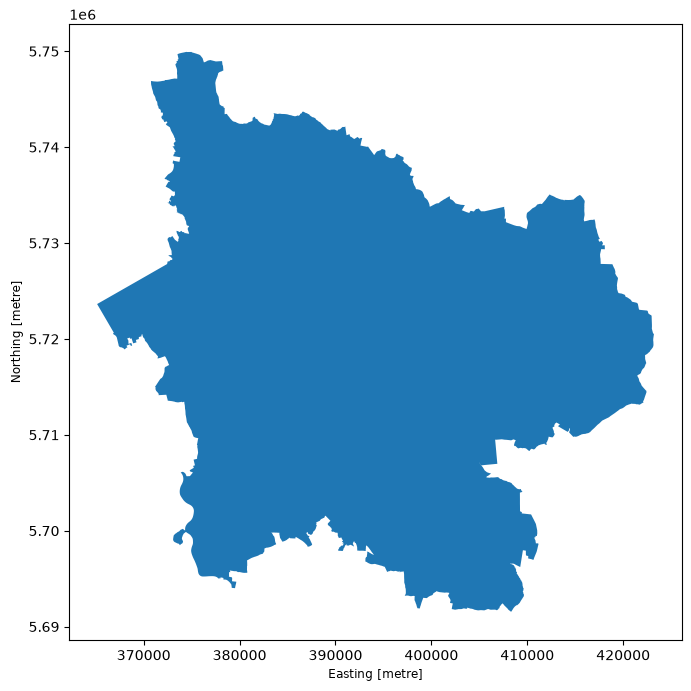

In [22]:
test = shapefiles[3]
print(test)
gdf=gpd.read_file(os.path.join(shape_dir, test))
print(gdf.head())
gdf.plot(figsize=(8, 8))

In [ ]:
print(gdf.crs)

In [ ]:
gdf_ll = gdf.to_crs("EPSG:4326")

In [ ]:
gdf_ll.to_file(os.path.join(shape_dir,"KARE_latlon.shp"))


In [ ]:
gdf_test=gpd.read_file(os.path.join(shape_dir, "KARE_latlon.shp"))
gdf_test.plot()

In [ ]:
shape_dir = os.path.join(wkd,'Shapefiles_Nukleus')
new_dir = os.path.join(wkd,'New_Shapefiles_Nukleus')
shapefiles = [f for f in os.listdir(shape_dir) if f.endswith('.shp')]
for shapefile in shapefiles:
    shapefile_path = os.path.join(shape_dir, shapefile)
    gdf = gpd.read_file(shapefile_path)
    outfile = shapefile.replace(".shp", "_latlon.shp")
    gdf_ll = gdf.to_crs("EPSG:4326")
    new_shapefile_path = os.path.join(new_dir, outfile)
    gdf_ll.to_file(new_shapefile_path)
    print(shapefile)



In [6]:

shape_dir = os.path.join(wkd,'Shapefiles_Nukleus')
new_dir = os.path.join(wkd,'New_Shapefiles_Nukleus')
shapefiles = [f for f in os.listdir(shape_dir) if f.endswith('.shp')]
gdfs = []

for shapefile in shapefiles:
    shapefile_path = os.path.join(shape_dir, shapefile)
    gdf = gpd.read_file(shapefile_path)
    outfile = shapefile.replace(".shp", "_latlon.shp")
    gdf_ll = gdf.to_crs("EPSG:4326")
    gdf_ll["region"] = Path(shapefile).stem
  
    gdfs.append(gdf_ll[["region", "geometry"]])

    new_shapefile_path = os.path.join(new_dir, outfile)
    gdf_ll.to_file(new_shapefile_path)
    print(shapefile)

gdf_all = gpd.GeoDataFrame(
    pd.concat(gdfs, ignore_index=True),
    crs=gdfs[0].crs
)   

shapefile_all_path = os.path.join(new_dir, "regions_merged.shp")
print(shapefile_all_path)

gdf_all["geometry"] = gdf_all.geometry.apply(
    lambda g: Polygon(g) if g.geom_type == "LineString" else g
)
print(gdf_all)
gdf_all.to_file(shapefile_all_path)



KARE.shp
Duisburg_3x3.shp
klimakonform.shp
IAWAK-EE.shp
WAKOS_Festland.shp
ISAP.shp
/Users/Buelow/github/udag/New_Shapefiles_Nukleus/regions_merged.shp
           region                                           geometry
0            KARE  POLYGON ((11.43016 47.98022, 11.43071 47.97905...
1    Duisburg_3x3  POLYGON ((6.46907 51.17857, 6.98961 51.2285, 6...
2    klimakonform  MULTIPOLYGON (((11.44677 51.1945, 11.44538 51....
3        IAWAK-EE  POLYGON ((13.16349 51.75487, 13.16345 51.75487...
4  WAKOS_Festland  MULTIPOLYGON (((6.86501 53.5911, 6.86554 53.59...
5            ISAP  MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6...


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

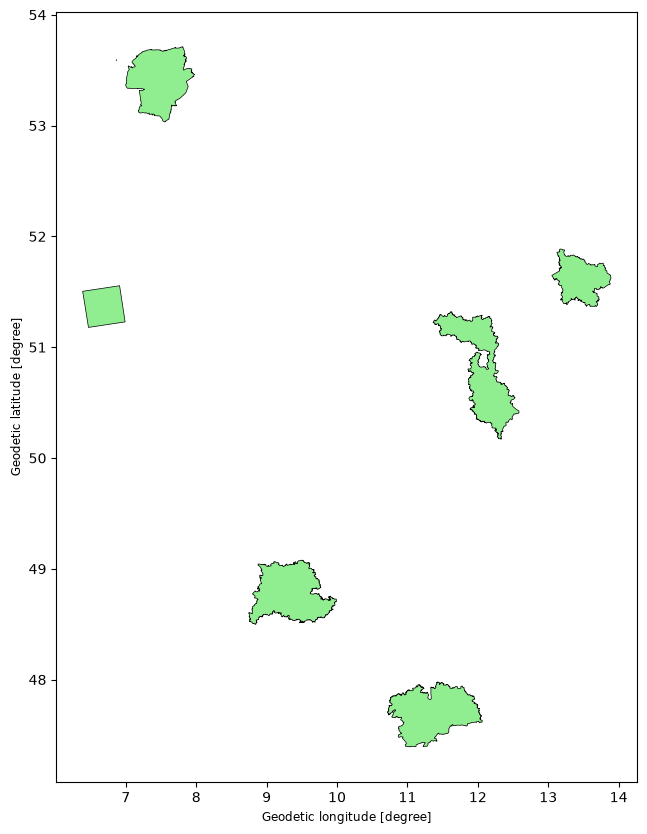

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

gdf_all.plot(
    ax=ax,
    facecolor="lightgreen",
    edgecolor="black",
    linewidth=0.5
)

Index


In [ ]:
# Index öffnen
file_index =os.path.join(wkd,'test_index','TG_HYR-LAEA-5_MPI-ESM1-2-HR_historical_r1i1p1f1_DWD_EPISODES-2025_v1-r1_day_bias-adjusted-interpolated_GERICS_sem_200201-201110.nc')
print(file_index)


In [ ]:
ds=xr.open_dataset(file_index, decode_timedelta=False)
ds.lat.values

In [ ]:
ds

In [ ]:
ds=xr.open_dataset(file_index, decode_timedelta=False)
#ds.TG.plot(figsize=(10,5))
ds.TG.isel(time=0).plot(figsize=(10,5))


Andere Shapefile:

In [26]:

shp_file= os.path.join(wkd,'eva-suite', 'UDAG_EvaSuite_allpolygones_regiklim_msf_200226.gpkg') 
gdf = gpd.read_file(shp_file)
print(gdf.head())
print(gdf.crs)

  id_9  id_8          NAME_0  id_6  id  id_0  id_1  id_2  id_3  id_4  id_5  \
0    1   NaN        IAWAK-EE   NaN NaN   NaN   NaN   NaN   NaN   NaN   NaN   
1    2   NaN    klimakonform   NaN NaN   NaN   NaN   NaN   NaN   NaN   NaN   
2    3   NaN  WAKOS_Festland   NaN NaN   NaN   NaN   NaN   NaN   NaN   NaN   
3    4   NaN            KARE   NaN NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4    5   NaN            ISAP   NaN NaN   NaN   NaN   NaN   NaN   NaN   NaN   

   id_7                                           geometry  
0   NaN  MULTIPOLYGON (((13.16349 51.75487, 13.16345 51...  
1   NaN  MULTIPOLYGON (((11.44677 51.1945, 11.44538 51....  
2   NaN  MULTIPOLYGON (((6.86501 53.5911, 6.86554 53.59...  
3   NaN  MULTIPOLYGON (((11.43016 47.98022, 11.43071 47...  
4   NaN  MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6...  
EPSG:4326


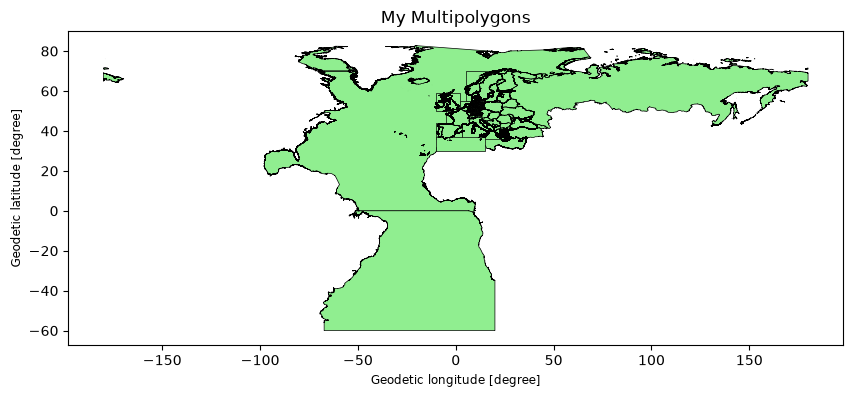

In [9]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

gdf.plot(
    ax=ax,
    facecolor="lightgreen",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title("My Multipolygons")
plt.show()

In [ ]:
gdf = gpd.read_file(shp_file)

print(gdf.head())
print(gdf.columns)
print(gdf['NAME_0'].unique())

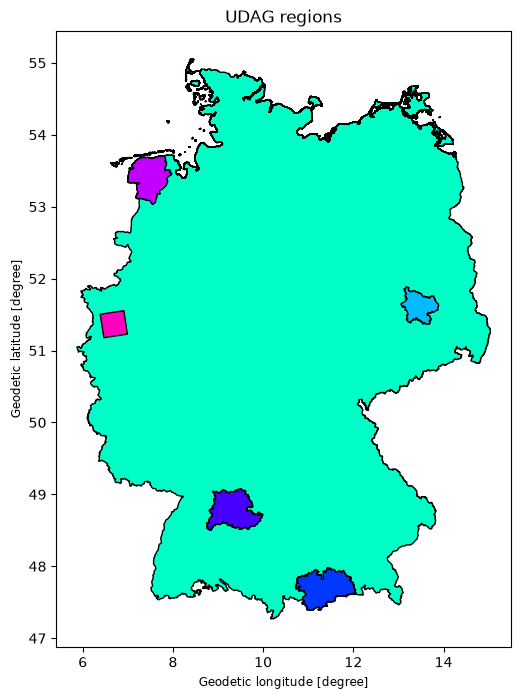

In [ ]:
regions = [
    "Germany",
    "KARE",
    "Duisburg_3x3",
    "klimakonform",
    "IAWAK-EE",
    "WAKOS_Festland",
    "ISAP"
]
#regions = ["Germany", "IAWAK-EE","WAKOS_Festland"]
gdf_sel = gdf[gdf["NAME_0"].isin(regions)]

fig, ax = plt.subplots(figsize=(8, 8))

gdf_sel.plot(
    ax=ax,
    edgecolor="black",
    cmap="gist_rainbow"
)
ax.set_title("UDAG regions")
plt.show()

In [42]:

shp_file= os.path.join(wkd,'eva-suite', 'UDAG_EvaSuite_allpolygones_regiklim_msf_200226.gpkg') 
gdf = gpd.read_file(shp_file)


# gewünschte Regionen auswählen
regions = [
    "Germany",
    "KARE",
    "Duisburg_3x3",
    "klimakonform",
    "IAWAK-EE",
    "WAKOS_Festland",
    "ISAP"
]
gdf_region = gdf[gdf["NAME_0"].isin(regions)].copy()

# Spalte umbenennen
gdf_region = gdf_region.rename(columns={"NAME_0": "region"})

# optional: nur die neue Spalte und die Geometrie behalten
gdf_region = gdf_region[["region", "geometry"]]


print(gdf_region)

# speichern
gdf_region.to_file(
    "udag_regions.gpkg",
    driver="GPKG"
)
gdf_region.to_file(
    "udag_regions.shp"
)

print(gdf_region["region"].unique())

             region                                           geometry
0          IAWAK-EE  MULTIPOLYGON (((13.16349 51.75487, 13.16345 51...
1      klimakonform  MULTIPOLYGON (((11.44677 51.1945, 11.44538 51....
2    WAKOS_Festland  MULTIPOLYGON (((6.86501 53.5911, 6.86554 53.59...
3              KARE  MULTIPOLYGON (((11.43016 47.98022, 11.43071 47...
4              ISAP  MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6...
5      Duisburg_3x3  MULTIPOLYGON (((6.46907 51.17857, 6.38699 51.5...
591         Germany  MULTIPOLYGON (((8.66879 47.69019, 8.66709 47.6...
651        IAWAK-EE  MULTIPOLYGON (((13.16349 51.75487, 13.16345 51...
656            KARE  MULTIPOLYGON (((11.43016 47.98022, 11.43071 47...
657            ISAP  MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6...
659  WAKOS_Festland  MULTIPOLYGON (((6.86501 53.5911, 6.86554 53.59...
662    Duisburg_3x3  MULTIPOLYGON (((6.46907 51.17857, 6.98961 51.2...
<ArrowStringArray>
[      'IAWAK-EE',   'klimakonform', 'WAKOS_Festland',    

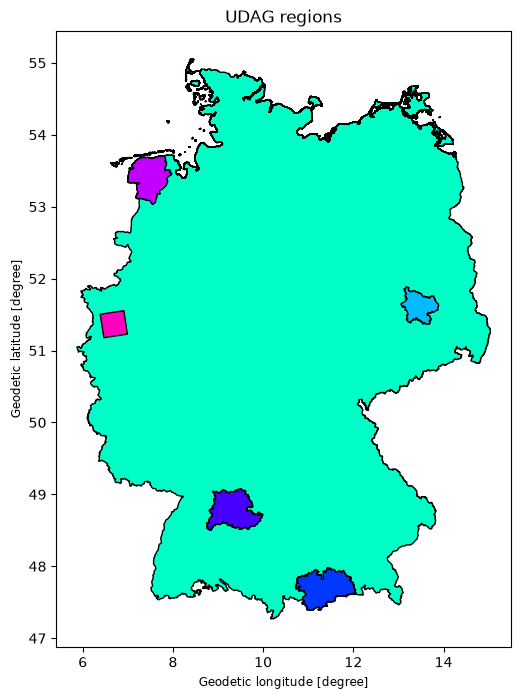

In [44]:
# check
shp_file= os.path.join(wkd,'udag_regions.shp') 
gdf = gpd.read_file(shp_file)

fig, ax = plt.subplots(figsize=(8, 8))

gdf.plot(
    ax=ax,
    edgecolor="black",
    cmap="gist_rainbow"
)
ax.set_title("UDAG regions")
plt.show()


In [ ]:
from shapely.ops import unary_union

geom = unary_union(gdf_sel.geometry)

gdf_merged = gpd.GeoDataFrame(
    {"region": ["EastGermany"]},
    geometry=[geom],
    crs=gdf.crs
)

gdf_merged.plot(figsize=(8, 8), edgecolor="black")
plt.show()

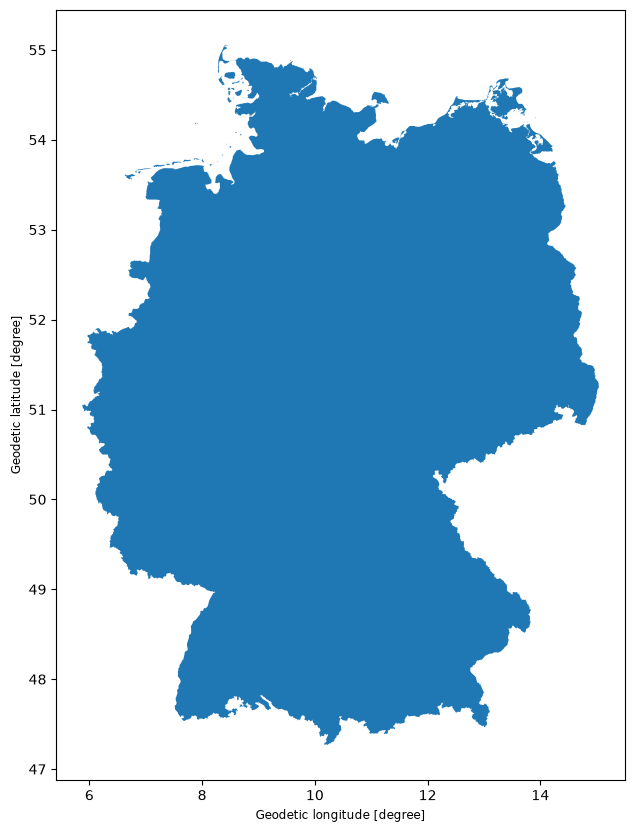

In [40]:
gdf_de = gdf[gdf["NAME_0"] == "Germany"]

gdf_de.plot(figsize=(8, 10))
plt.show()

In [ ]:
# I'm searching for Deutschland,  Sachsen Anhalt, Ostfriesland
#print(gdf.head())
#if 'Sachsen Anhalt' in gdf['NAME_0'].unique():
#    print("Sachsen Anhalt is present in the dataset.")
list=gdf['NAME_0'].unique()
#for item in list:
    #print(item)

matches = [x for x in list if "riesland" in x.lower()]

print(matches)


In [ ]:
import geopandas as gpd

# gewünschte Regionen auswählen
regions = [
    "Germany_Thueringen",
    "Germany_Sachsen",
    "Germany_Sachsen-Anhalt",
    "Germany"
]

gdf_region = gdf[gdf["NAME_0"].isin(regions)].copy()

# Spalte umbenennen
gdf_region = gdf_region.rename(columns={"NAME_0": "region"})

# optional: nur die neue Spalte und die Geometrie behalten
gdf_region = gdf_region[["region", "geometry"]]


# anhängen
gdf_region_all = gpd.pd.concat(
    [gdf_region, gdf_merged],
    ignore_index=True
)

print(gdf_region_all)

# speichern
gdf_region.to_file(
    "east_germany_and_germanyregions.gpkg",
    driver="GPKG"
)

print(gdf_region["region"].unique())

In [ ]:
gdf_regions = (
    gdf_region_all
    .dissolve(by="region")
    .reset_index()
)[["region", "geometry"]]

In [ ]:
gdf_regions

In [ ]:
# Read, select columns and merge
adm_selected_merged = []
selected_columns = ['NAME_0', 'geometry']
for f in admfiles:
    gdf = gpd.read_file(f)
    # keep only the columns that exist in this file
    cols_present = [c for c in selected_columns if c in gdf.columns]
    gdf_sel = gdf[cols_present].copy()

    # add missing columns so we can concatenate consistently
    for c in selected_columns:
        if c not in gdf_sel.columns:
            gdf_sel[c] = None

    # ensure column order
    gdf_sel = gdf_sel[selected_columns]
    #print(gdf_sel.head(3))
    adm_selected_merged.append(gdf_sel)


# Save to a single shapefile (optional)
output_adm_selected_shp = os.path.join(adm_reg_dir, 'adm_selected_merged_BKF_TGO_CIV.shp')
os.makedirs(os.path.dirname(output_adm_selected_shp), exist_ok=True)
# concatenate the list into a single GeoDataFrame before saving
gpd.GeoDataFrame(pd.concat(adm_selected_merged, ignore_index=True), crs=crs).to_file(output_adm_selected_shp)

# preview the first rows of the concatenated result
pd.concat(adm_selected_merged, ignore_index=True).head(3)